# 07 — Dataset compatibility (PKU vs DeepPCB)
Chạy độc lập từ thư mục project hoặc thư mục con. Notebook **đọc** nhãn/ảnh gốc của từng dataset; không merge, train, chuyển annotation, thay split hoặc xuất CSV. Bảng và minh họa được tạo từ dữ liệu thật khi chạy. Quy tắc tương đương ngữ nghĩa được nêu minh bạch: mã nguồn kiểm chứng tên lớp, ID, số box, hình dạng/miền ảnh và minh họa; không thể chứng minh hoàn toàn bản chất vật lý chỉ bằng so khớp chuỗi hay số pixel.

In [1]:
import json
import re
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, Markdown
notebook_path = next((p / 'scripts' / '01_inventory.ipynb' for p in (Path.cwd(), *Path.cwd().parents) if (p / 'scripts' / '01_inventory.ipynb').is_file()), None)
if notebook_path is None: raise FileNotFoundError('Chạy notebook từ bên trong project; thiếu scripts/01_inventory.ipynb')
exec(compile(''.join(json.loads(notebook_path.read_text(encoding='utf-8'))['cells'][1]['source']), str(notebook_path), 'exec'))
audits = all_audits()
pku, deep = audits['PKU'], audits['DeepPCB']
assert pku['classes'] == ['Missing_hole', 'Mouse_bite', 'Open_circuit', 'Short', 'Spur', 'Spurious_copper']
assert set(deep['classes']) == {'open', 'short', 'mousebite', 'spur', 'copper', 'pin-hole'}
assert len(pku['boxes']) == pku['counts']['boxes'].sum() and len(deep['boxes']) == deep['counts']['boxes'].sum(), 'Có box không hợp lệ; xem notebook 02 trước khi diễn giải'
display(Markdown('## Kiểm chứng nhãn và số lượng từ Class.txt + annotation gốc'))
for name, audit in audits.items():
    display(Markdown(f'### {name}: định dạng ' + ('YOLO chuẩn hóa, class ID 0–5' if name == 'PKU' else 'x1 y1 x2 y2 pixel, class ID 1–6')))
    counts = audit['by_class'].pivot(index='class', columns='split', values='boxes').reindex(index=audit['classes'], columns=SPLITS).fillna(0).astype(int)
    counts['total'] = counts.sum(axis=1)
    display(counts)
    display(audit['counts'].set_index('split')[['images', 'labels', 'boxes']])


/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## Kiểm chứng nhãn và số lượng từ Class.txt + annotation gốc

### DeepPCB: định dạng x1 y1 x2 y2 pixel, class ID 1–6

split,train,valid,test,total
class,,,,
open,1562,189,191,1942
short,1169,167,170,1506
mousebite,1582,189,194,1965
spur,1307,165,153,1625
copper,1186,148,140,1474
pin-hole,1218,147,136,1501


,images,labels,boxes
split,,,
train,1200,1200,8024
valid,150,150,1005
test,150,150,984


### PKU: định dạng YOLO chuẩn hóa, class ID 0–5

split,train,valid,test,total
class,,,,
Missing_hole,1988,223,223,2434
Mouse_bite,1968,221,221,2410
Open_circuit,1928,205,205,2338
Short,1964,216,216,2396
Spur,1952,217,217,2386
Spurious_copper,2012,225,225,2462


,images,labels,boxes
split,,,
train,2772,2772,11812
valid,366,366,1307
test,366,366,1307


## Quy tắc ánh xạ được kiểm chứng bằng mã
Bốn cặp tên khác nhau do viết hoa, dấu gạch dưới hoặc hậu tố `circuit` được ghép trực tiếp khi cùng loại lỗi. `Spurious_copper`/`copper` là ứng viên **có điều kiện**: cùng mô tả đồng dư, nhưng phải kiểm tra ngữ nghĩa nhãn trên ảnh trước khi đánh giá chung. `Missing_hole` là thiếu lỗ khoan đáng lẽ phải có; `pin-hole` là lỗ kim nhỏ xuất hiện trên vùng đồng, khác bản chất vật lý. Quy tắc ngữ nghĩa này là quyết định chuyên môn, **không** phải kết luận thống kê suy ra tự động từ tên file. Bên dưới kiểm tra từng tên có thật trong Class.txt và mỗi lớp có box, rồi hiển thị crop để hỗ trợ đối chiếu.

In [2]:
# Quy tắc ngữ nghĩa khai báo riêng với dữ liệu quan sát; không gán lại class_id và không sửa label.
candidates = {'Missing_hole': ('pin-hole', 'khác bản chất'), 'Mouse_bite': ('mousebite', 'tương đương'), 'Open_circuit': ('open', 'tương đương'), 'Short': ('short', 'tương đương'), 'Spur': ('spur', 'tương đương'), 'Spurious_copper': ('copper', 'cần xác nhận')}
assert set(candidates) == set(pku['classes']) and {x[0] for x in candidates.values()} == set(deep['classes'])
p_counts = pku['by_class'].groupby('class')['boxes'].sum()
d_counts = deep['by_class'].groupby('class')['boxes'].sum()
rows = []
for number, name in enumerate(pku['classes'], 1):
    counterpart, rule = candidates[name]
    assert p_counts[name] > 0 and d_counts[counterpart] > 0, (name, counterpart)
    status = {'tương đương': 'Khớp 1-1', 'cần xác nhận': 'Khớp có điều kiện', 'khác bản chất': 'Không khớp'}[rule]
    advice = {'Khớp 1-1': 'Có thể so sánh trên lớp này khi đánh giá domain-shift', 'Khớp có điều kiện': 'Chỉ so sánh sau khi xác nhận định nghĩa đồng dư trên ảnh', 'Không khớp': 'Không gán chung class ID; loại khỏi đánh giá 5 lớp'}[status]
    rows.append({'STT': number, 'PKU class': name, 'DeepPCB class': counterpart, 'Trạng thái ánh xạ': status, 'Nhận định xử lý': advice, 'PKU boxes': int(p_counts[name]), 'DeepPCB boxes': int(d_counts[counterpart])})
mapping = pd.DataFrame(rows)
display(mapping[['STT', 'PKU class', 'DeepPCB class', 'Trạng thái ánh xạ', 'Nhận định xử lý']])
display(Markdown('### Bằng chứng số box thực tế cho từng cặp (không đổi ID nhãn)'))
display(mapping[['PKU class', 'PKU boxes', 'DeepPCB class', 'DeepPCB boxes']])
display(mapping['Trạng thái ánh xạ'].value_counts().rename_axis('Trạng thái').reset_index(name='Số lớp'))


,STT,PKU class,DeepPCB class,Trạng thái ánh xạ,Nhận định xử lý
0,1,Missing_hole,pin-hole,Không khớp,Không gán chung class ID; loại khỏi đánh giá 5...
1,2,Mouse_bite,mousebite,Khớp 1-1,Có thể so sánh trên lớp này khi đánh giá domai...
2,3,Open_circuit,open,Khớp 1-1,Có thể so sánh trên lớp này khi đánh giá domai...
3,4,Short,short,Khớp 1-1,Có thể so sánh trên lớp này khi đánh giá domai...
4,5,Spur,spur,Khớp 1-1,Có thể so sánh trên lớp này khi đánh giá domai...
5,6,Spurious_copper,copper,Khớp có điều kiện,Chỉ so sánh sau khi xác nhận định nghĩa đồng d...


### Bằng chứng số box thực tế cho từng cặp (không đổi ID nhãn)

,PKU class,PKU boxes,DeepPCB class,DeepPCB boxes
0,Missing_hole,2434,pin-hole,1501
1,Mouse_bite,2410,mousebite,1965
2,Open_circuit,2338,open,1942
3,Short,2396,short,1506
4,Spur,2386,spur,1625
5,Spurious_copper,2462,copper,1474


,Trạng thái,Số lớp
0,Khớp 1-1,4
1,Không khớp,1
2,Khớp có điều kiện,1


## Minh họa lấy trực tiếp từ bbox nhãn gốc: các cặp cần thẩm định ngữ nghĩa

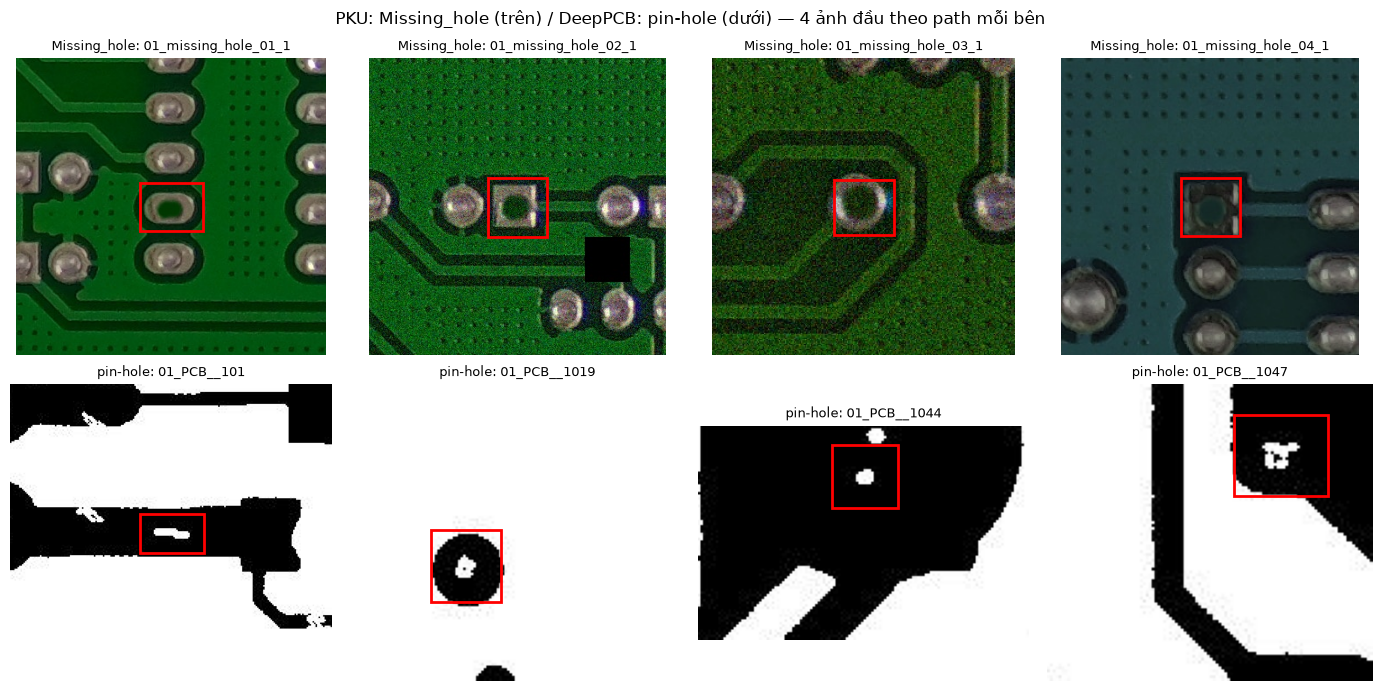

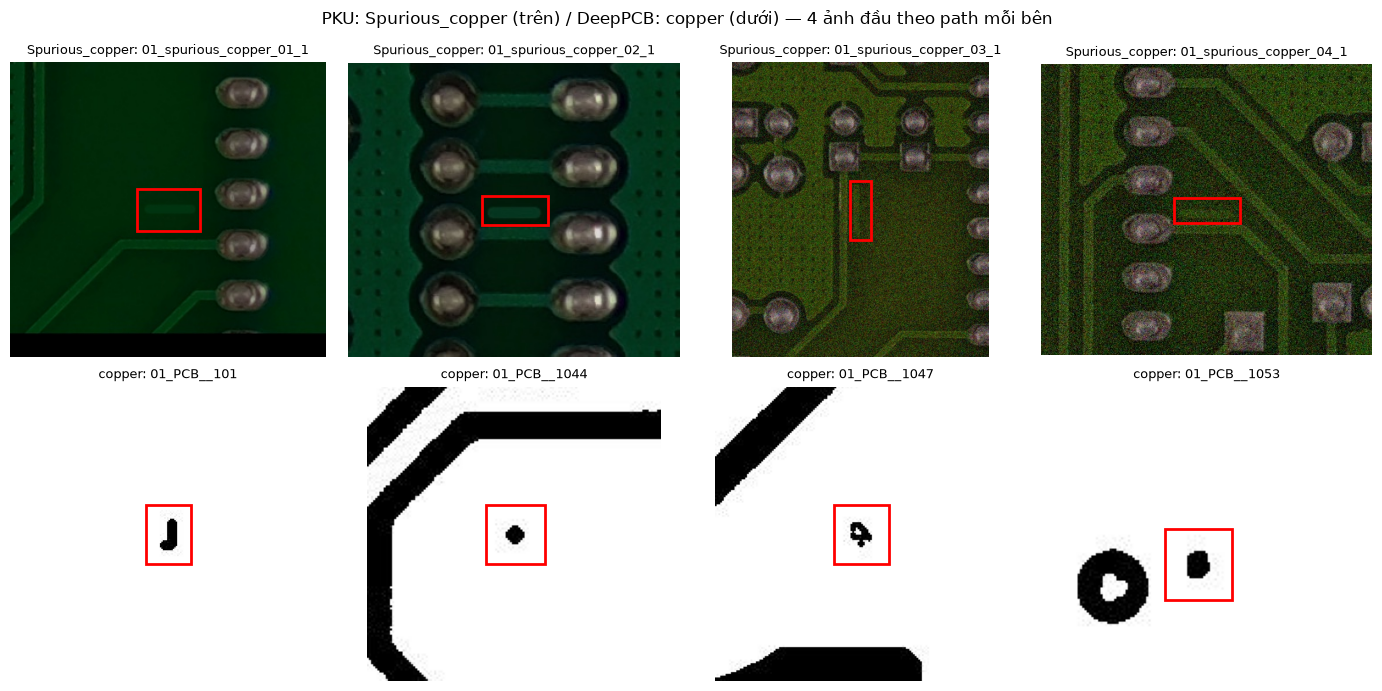

In [3]:
display(Markdown('## Minh họa lấy trực tiếp từ bbox nhãn gốc: các cặp cần thẩm định ngữ nghĩa'))
def show_crop(audit, class_name, ax, n):
    # Lấy các ảnh khác nhau theo thứ tự ổn định; không chọn ảnh theo kết quả mong muốn.
    subset = audit['boxes'].query('`class` == @class_name').drop_duplicates('image').sort_values('image').iloc[n]
    with Image.open(ROOT / subset['image']) as im:
        width, height = im.size
        pad = max(24, int(max(subset.width_px, subset.height_px) * 2))
        x0, y0 = max(0, int(subset.x1) - pad), max(0, int(subset.y1) - pad)
        x3, y3 = min(width, int(subset.x2) + pad), min(height, int(subset.y2) + pad)
        crop = im.convert('RGB').crop((x0, y0, x3, y3))
    ax.imshow(crop)
    ax.add_patch(Rectangle((subset.x1 - x0, subset.y1 - y0), subset.width_px, subset.height_px, fill=False, edgecolor='red', linewidth=2))
    ax.set_title(f'{class_name}: {Path(subset.image).stem}', fontsize=9)
    ax.axis('off')
for left, right in [('Missing_hole', 'pin-hole'), ('Spurious_copper', 'copper')]:
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for i in range(4):
        show_crop(pku, left, axes[0, i], i)
        show_crop(deep, right, axes[1, i], i)
    fig.suptitle(f'PKU: {left} (trên) / DeepPCB: {right} (dưới) — 4 ảnh đầu theo path mỗi bên')
    plt.tight_layout()
    plt.show()


## Khác biệt miền ảnh và tỷ lệ kích thước box (đo từ dữ liệu gốc)

,dataset,images,dominant_resolution,resolution_count,image_modes,median_relative_box_area,median_box_width_px,median_box_height_px
0,DeepPCB,1500,"(640, 640)",1,"{'L': 1462, 'RGB': 38}",0.002891,35.0,33.0
1,PKU,3504,"(3056, 2464)",1408,{'RGB': 3504},0.000885,64.0,62.0


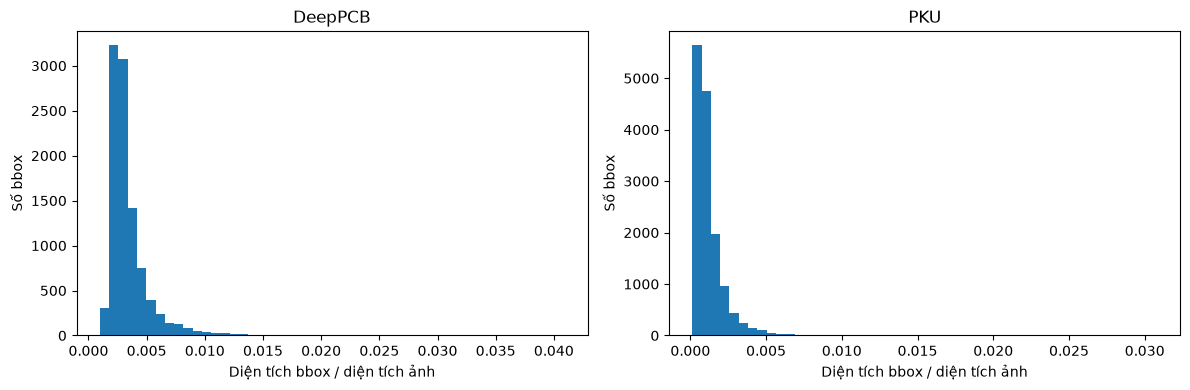

In [4]:
display(Markdown('## Khác biệt miền ảnh và tỷ lệ kích thước box (đo từ dữ liệu gốc)'))
domain_rows = []
for name, audit in audits.items():
    paths = [p for split in SPLITS for p in sorted((ROOT / 'data/raw' / DATASETS[name][0] / split / 'images').iterdir()) if p.suffix.lower() in IMAGE_EXTS]
    resolutions, modes = Counter(), Counter()
    for path in paths:
        with Image.open(path) as im:
            resolutions[im.size] += 1
            modes[im.mode] += 1
    domain_rows.append({'dataset': name, 'images': len(paths), 'dominant_resolution': str(resolutions.most_common(1)[0][0]), 'resolution_count': len(resolutions), 'image_modes': dict(modes), 'median_relative_box_area': audit['boxes']['relative_area'].median(), 'median_box_width_px': audit['boxes']['width_px'].median(), 'median_box_height_px': audit['boxes']['height_px'].median()})
domain = pd.DataFrame(domain_rows)
display(domain)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, audit) in zip(axes, audits.items()):
    ax.hist(audit['boxes']['relative_area'], bins=50)
    ax.set(title=name, xlabel='Diện tích bbox / diện tích ảnh', ylabel='Số bbox')
plt.tight_layout()
plt.show()


In [5]:
compatible = mapping[mapping['Trạng thái ánh xạ'] != 'Không khớp']
conditional = mapping[mapping['Trạng thái ánh xạ'] == 'Khớp có điều kiện']
incompatible = mapping[mapping['Trạng thái ánh xạ'] == 'Không khớp']
assert len(compatible) == 5 and len(incompatible) == 1 and len(conditional) == 1
assert incompatible.iloc[0]['PKU class'] == 'Missing_hole' and incompatible.iloc[0]['DeepPCB class'] == 'pin-hole'
conclusion = (f'Từ Class.txt và annotation gốc: {len(compatible)}/{len(mapping)} lớp có thể ánh xạ ({len(conditional)} cặp cần xác nhận ngữ nghĩa: {conditional.iloc[0]["PKU class"]} ↔ {conditional.iloc[0]["DeepPCB class"]}); {incompatible.iloc[0]["PKU class"]} không tương đương {incompatible.iloc[0]["DeepPCB class"]}. '              f'PKU có {int(pku["counts"].images.sum()):,} ảnh và {int(pku["counts"].boxes.sum()):,} box; DeepPCB có {int(deep["counts"].images.sum()):,} ảnh và {int(deep["counts"].boxes.sum()):,} box. '              'Không nên merge DeepPCB vào train/validation/test của PKU. Ưu tiên PKU làm dataset chính. DeepPCB chỉ nên là external test/domain-shift nếu còn thời gian: chỉ đánh giá 5 lớp ánh xạ được sau khi xác nhận cặp có điều kiện, không fine-tune trên DeepPCB và không chọn lại threshold theo external test. '              'Missing_hole là thiếu lỗ khoan đáng lẽ phải có; pin-hole là lỗ kim xuất hiện trên vùng đồng: khác bản chất vật lý nên không gộp cùng class ID. Các crop hỗ trợ kiểm tra định nghĩa, không tự động chứng minh mọi nhãn đúng.')
display(Markdown('## Kết luận từ bảng ánh xạ và thống kê đã tính'))
display(Markdown(conclusion))
doc = ROOT / 'docs' / 'data_audit.md'
if doc.exists():
    section = '## Dataset compatibility (phase 07)\n\n' + conclusion
    prior = doc.read_text(encoding='utf-8')
    if '## Dataset compatibility (phase 07)' not in prior:
        with doc.open('a', encoding='utf-8') as out: out.write(('\n' if prior and not prior.endswith('\n') else '') + '\n' + section + '\n')
    display(Markdown('Đã ghi kết luận vào `docs/data_audit.md` (chỉ thêm một lần).'))
else:
    display(Markdown('docs/data_audit.md chưa tồn tại; kết luận vẫn hiển thị ở đây.'))


## Kết luận từ bảng ánh xạ và thống kê đã tính

Từ Class.txt và annotation gốc: 5/6 lớp có thể ánh xạ (1 cặp cần xác nhận ngữ nghĩa: Spurious_copper ↔ copper); Missing_hole không tương đương pin-hole. PKU có 3,504 ảnh và 14,426 box; DeepPCB có 1,500 ảnh và 10,013 box. Không nên merge DeepPCB vào train/validation/test của PKU. Ưu tiên PKU làm dataset chính. DeepPCB chỉ nên là external test/domain-shift nếu còn thời gian: chỉ đánh giá 5 lớp ánh xạ được sau khi xác nhận cặp có điều kiện, không fine-tune trên DeepPCB và không chọn lại threshold theo external test. Missing_hole là thiếu lỗ khoan đáng lẽ phải có; pin-hole là lỗ kim xuất hiện trên vùng đồng: khác bản chất vật lý nên không gộp cùng class ID. Các crop hỗ trợ kiểm tra định nghĩa, không tự động chứng minh mọi nhãn đúng.

Đã ghi kết luận vào `docs/data_audit.md` (chỉ thêm một lần).